# Лабораторная работа № 3. Оптимизация гиперпараметров

**Задача:** классификация Titanic из лабораторной № 2.
**Модель:** GradientBoostingClassifier. **Критерий поиска:** F1 класса Survived = 1, больше — лучше.

Сравниваются исходная модель, GridSearchCV и RandomizedSearchCV.
Данные, признаки, предобработка, train/test и CV зафиксированы для всех вариантов.
Источники: `lab03.pdf`, `preza.pdf`, результаты лабораторной № 2.

## 1. Настройки эксперимента

Используются версии зависимостей лабораторной № 2 (`../classification/requirements.txt`).

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import randint, loguniform
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV, ParameterGrid,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 5
N_JOBS = 1
RANDOM_ITERATIONS = 27
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
%matplotlib inline

print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.6.1


## 2. Данные и воспроизводимость baseline

Используется ранее опубликованный `classification/data/titanic.csv`.
Сохранены семь признаков и стратифицированное разбиение лабораторной № 2.

In [2]:
DATA_PATH = Path('../classification/data/titanic.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('classification/data/titanic.csv')
data = pd.read_csv(DATA_PATH)

numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
feature_columns = numeric_features + categorical_features
X = data[feature_columns].copy()
y = data['Survived'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

assert {'Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'}.isdisjoint(X.columns)
assert X_train.index.intersection(X_test.index).empty
display(pd.DataFrame({
    'N': [len(y_train), len(y_test)],
    'Survived=1': [int(y_train.sum()), int(y_test.sum())],
    'Доля класса 1': [y_train.mean(), y_test.mean()],
}, index=['Train', 'Test']).round(4))

,N,Survived=1,Доля класса 1
Train,712,273,0.3834
Test,179,69,0.3855


Тестовое разбиение уже использовалось в лабораторной № 2: его качество исходной модели известно.
Оно повторно используется как фиксированная сравнительная выборка, а не объявляется новым слепым тестом.
Пространства поиска и правило выбора задаются заранее по смыслу гиперпараметров.
В лабораторной № 3 test не передаётся в подбор и оценивается только после фиксации решения;
параметры по итоговым тестовым результатам не корректируются.

Исходная модель — Gradient Boosting из лабораторной № 2:
200 деревьев, learning_rate=0.05, max_depth=3, min_samples_leaf=5.
Предобработка сохранена: медиана числовых признаков, мода категорий, One-Hot;
масштабирование деревьям не требуется. Статистики вычисляются внутри Pipeline.

In [3]:
BASELINE_PARAMS = {
    'n_estimators': 200,
    'learning_rate': 0.05,
    'max_depth': 3,
    'min_samples_leaf': 5,
    'random_state': RANDOM_STATE,
}


def make_model():
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features),
    ])
    return Pipeline([
        ('preprocess', preprocess),
        ('classifier', GradientBoostingClassifier(**BASELINE_PARAMS)),
    ])


baseline_model = make_model()
display(pd.Series(BASELINE_PARAMS, name='Исходные настройки'))

n_estimators        200.00
learning_rate         0.05
max_depth             3.00
min_samples_leaf      5.00
random_state         42.00
Name: Исходные настройки, dtype: float64

## 3. Гиперпараметры и бюджет

| Гиперпараметр | Grid | Random | Ожидаемое влияние |
|---|---|---|---|
| n_estimators | 100, 200, 300 | целые от 100 до 300 включительно | Больше шагов уточнения; растут время и риск подгонки |
| learning_rate | 0.03, 0.05, 0.10 | log-uniform на [0.03, 0.10] | Меньший вклад дерева обычно требует большего числа шагов |
| max_depth | 1, 3, 5 | целые от 1 до 5 включительно | Глубже дерево — сложнее взаимодействия и выше риск переобучения |

Границы числовых пространств общие. Grid проверяет 27 комбинаций;
Random — 27 случайных точек в более плотном пространстве тех же границ.
Это сравнение способов покрытия области, а не случайная перестановка тех же 27 точек сетки.

In [4]:
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.03, 0.05, 0.10],
    'classifier__max_depth': [1, 3, 5],
}
param_distributions = {
    'classifier__n_estimators': randint(100, 301),
    'classifier__learning_rate': loguniform(0.03, 0.10),
    'classifier__max_depth': randint(1, 6),
}
grid_candidates = len(ParameterGrid(param_grid))
assert grid_candidates == RANDOM_ITERATIONS == 27
print('Grid:', grid_candidates, 'вариантов,', grid_candidates * N_FOLDS, 'CV fit')
print('Random:', RANDOM_ITERATIONS, 'вариантов,', RANDOM_ITERATIONS * N_FOLDS, 'CV fit')
print('Плюс по одному итоговому refit на train для каждого поиска.')

Grid: 27 вариантов, 135 CV fit
Random: 27 вариантов, 135 CV fit
Плюс по одному итоговому refit на train для каждого поиска.


## 4. Кросс-валидация и исходное качество

Использованы пять стратифицированных фолдов: компромисс между числом проверок и стоимостью подбора.
В каждом validation около 142–143 пассажиров, доли классов сохранены.
Список индексов фолдов один раз зафиксирован и повторно используется во всех проверках.

In [5]:
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(splitter.split(X_train, y_train))
baseline_cv = cross_validate(
    baseline_model, X_train, y_train, cv=cv_splits,
    scoring='f1', return_train_score=True, n_jobs=N_JOBS,
    error_score='raise',
)
baseline_model.fit(X_train, y_train)
baseline_fold_scores = baseline_cv['test_score']
print(f'Исходный CV F1: {baseline_fold_scores.mean():.4f}')
print(f'Разброс по фолдам: {baseline_fold_scores.std():.4f}')
print('Отдельные фолды:', np.round(baseline_fold_scores, 4))

Исходный CV F1: 0.7588
Разброс по фолдам: 0.0410
Отдельные фолды: [0.8113 0.7048 0.7959 0.7222 0.76  ]


## 5. Grid Search

Полностью перебирается заданная сетка. Время включает 135 CV fit и итоговый refit победителя на train.
Параллелизм одинаков для обеих стратегий: n_jobs=1.

In [6]:
grid_search = GridSearchCV(
    make_model(), param_grid=param_grid, scoring='f1', cv=cv_splits,
    n_jobs=N_JOBS, return_train_score=True, refit=True, error_score='raise',
)
start = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start

grid_results = pd.DataFrame(grid_search.cv_results_)
print('Проверено комбинаций:', len(grid_results))
print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучший CV F1: {grid_search.best_score_:.4f}')
print(f'Время Grid Search: {grid_seconds:.2f} с')
display(grid_results[
    ['param_classifier__n_estimators', 'param_classifier__learning_rate',
     'param_classifier__max_depth', 'mean_train_score', 'mean_test_score',
     'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').round(4))

Проверено комбинаций: 27
Лучшие параметры: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 200}
Лучший CV F1: 0.7635
Время Grid Search: 11.50 с


,param_classifier__n_estimators,param_classifier__learning_rate,param_classifier__max_depth,mean_train_score,mean_test_score,std_test_score,rank_test_score
16,200,0.05,5,0.9334,0.7635,0.0364,1
14,300,0.05,3,0.8887,0.7619,0.0454,2
21,100,0.10,3,0.8617,0.7614,0.0392,3
5,300,0.03,3,0.8562,0.7613,0.0361,4
8,300,0.03,5,0.9281,0.7602,0.0414,5
22,200,0.10,3,0.9026,0.7594,0.0401,6
7,200,0.03,5,0.9034,0.7590,0.0406,7
13,200,0.05,3,0.8660,0.7588,0.0410,8
23,300,0.10,3,0.9292,0.7571,0.0282,9
15,100,0.05,5,0.8924,0.7564,0.0411,10


## 6. Random Search

Случайный поиск использует те же границы параметров, 27 комбинаций, общие фолды и random_state=42.
Время также включает refit, а тестовая часть не передаётся поиску.

In [7]:
random_search = RandomizedSearchCV(
    make_model(), param_distributions=param_distributions,
    n_iter=RANDOM_ITERATIONS, scoring='f1', cv=cv_splits,
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
    return_train_score=True, refit=True, error_score='raise',
)
start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start

random_results = pd.DataFrame(random_search.cv_results_)
print('Проверено комбинаций:', len(random_results))
print('Лучшие параметры:', random_search.best_params_)
print(f'Лучший CV F1: {random_search.best_score_:.4f}')
print(f'Время Random Search: {random_seconds:.2f} с')
display(random_results[
    ['param_classifier__n_estimators', 'param_classifier__learning_rate',
     'param_classifier__max_depth', 'mean_train_score', 'mean_test_score',
     'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').round(4))

Проверено комбинаций: 27
Лучшие параметры: {'classifier__learning_rate': 0.06252814456126575, 'classifier__max_depth': 3, 'classifier__n_estimators': 180}
Лучший CV F1: 0.7654
Время Random Search: 10.68 с


,param_classifier__n_estimators,param_classifier__learning_rate,param_classifier__max_depth,mean_train_score,mean_test_score,std_test_score,rank_test_score
17,180,0.0625,3,0.8706,0.7654,0.0370,1
16,298,0.0401,4,0.9163,0.7643,0.0371,2
21,113,0.0930,4,0.9109,0.7635,0.0380,3
1,120,0.0724,5,0.9258,0.7623,0.0443,4
13,188,0.0324,4,0.8753,0.7616,0.0287,5
23,181,0.0444,5,0.9245,0.7605,0.0400,6
3,199,0.0521,5,0.9340,0.7600,0.0427,7
10,207,0.0466,3,0.8596,0.7598,0.0360,8
5,257,0.0321,4,0.8935,0.7559,0.0337,9
22,289,0.0720,4,0.9526,0.7538,0.0332,10


## 7. Сравнение поисков и фиксация решения

Бюджеты одинаковы по числу комбинаций и фолдов. Различие времени зависит также от конкретных
чисел деревьев, глубин и текущей нагрузки; равенство wall-clock-бюджета не предполагается.
При равенстве среднего CV выбирается исходная/раньше указанная конфигурация без дополнительного перебора.

In [8]:
search_comparison = pd.DataFrame({
    'Комбинаций': [len(grid_results), len(random_results)],
    'CV fit': [len(grid_results) * N_FOLDS, len(random_results) * N_FOLDS],
    'Refit': [1, 1],
    'CV F1': [grid_search.best_score_, random_search.best_score_],
    'Время, с': [grid_seconds, random_seconds],
}, index=['Grid Search', 'Random Search'])
display(search_comparison.round(4))

cv_means = pd.Series({
    'Baseline': baseline_fold_scores.mean(),
    'Grid Search': grid_search.best_score_,
    'Random Search': random_search.best_score_,
})
selected_name = cv_means.idxmax()
models = {
    'Baseline': baseline_model,
    'Grid Search': grid_search.best_estimator_,
    'Random Search': random_search.best_estimator_,
}
final_model = models[selected_name]
print('Основное решение до открытия тестовой таблицы:', selected_name)
print('Его параметры:', {
    key: final_model.get_params()[key] for key in param_grid
})

,Комбинаций,CV fit,Refit,CV F1,"Время, с"
Grid Search,27,135,1,0.7635,11.4995
Random Search,27,135,1,0.7654,10.6783


Основное решение до открытия тестовой таблицы: Random Search
Его параметры: {'classifier__n_estimators': 180, 'classifier__learning_rate': 0.06252814456126575, 'classifier__max_depth': 3}


## 8. Влияние гиперпараметров

Для каждого параметра взят срез полной сетки при фиксации двух остальных на лучших значениях Grid Search.
Это контролируемое сравнение, а не усреднение неодинаковых конфигураций.
Показаны средняя F1 обучения и проверочных фолдов; полоса — межфолдовый разброс validation F1.
Дополнительное обучение и подбор по test не выполняются.

,Значение,mean_train_score,mean_test_score,std_test_score
15,100.0,0.8924,0.7564,0.0411
16,200.0,0.9334,0.7635,0.0364
17,300.0,0.9607,0.7537,0.0224


,Значение,mean_train_score,mean_test_score,std_test_score
7,0.03,0.9034,0.7590,0.0406
16,0.05,0.9334,0.7635,0.0364
25,0.10,0.9689,0.7421,0.0280


,Значение,mean_train_score,mean_test_score,std_test_score
10,1.0,0.7561,0.7512,0.0397
13,3.0,0.8660,0.7588,0.0410
16,5.0,0.9334,0.7635,0.0364


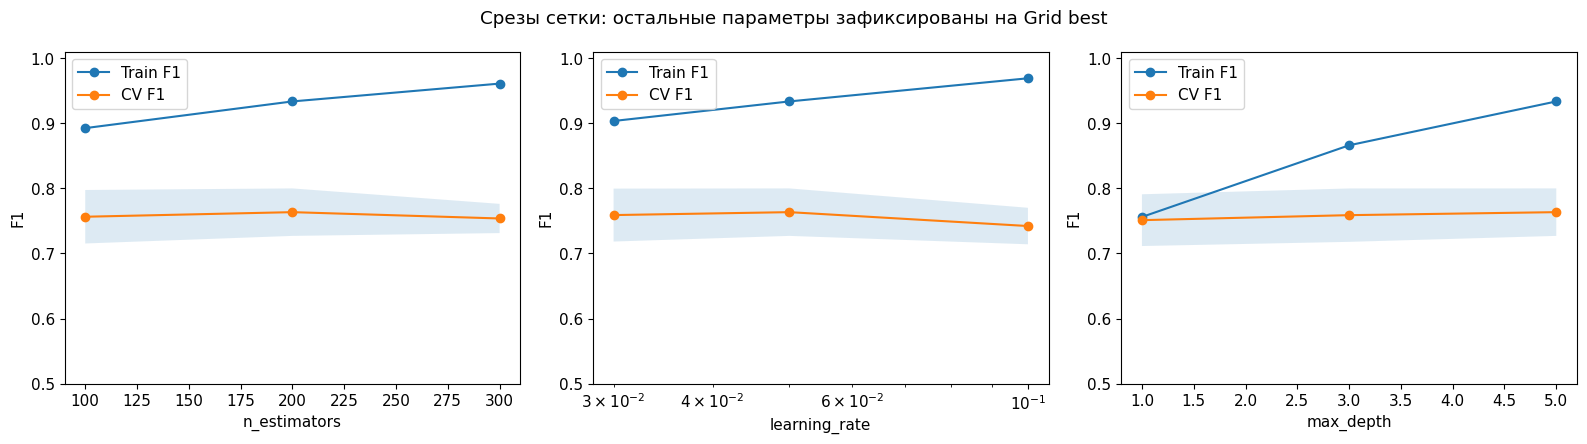

In [9]:
effect_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, parameter in zip(axes, param_grid):
    mask = np.ones(len(grid_results), dtype=bool)
    for other_parameter, best_value in grid_search.best_params_.items():
        if other_parameter != parameter:
            mask &= grid_results[f'param_{other_parameter}'].astype(float).eq(best_value).to_numpy()
    part = grid_results.loc[mask].copy()
    part['Значение'] = part[f'param_{parameter}'].astype(float)
    part = part.sort_values('Значение')
    effect_tables[parameter] = part[
        ['Значение', 'mean_train_score', 'mean_test_score', 'std_test_score']
    ]
    x_values = part['Значение'].to_numpy()
    validation = part['mean_test_score'].to_numpy()
    spread = part['std_test_score'].to_numpy()
    ax.plot(x_values, part['mean_train_score'], 'o-', label='Train F1')
    ax.plot(x_values, validation, 'o-', label='CV F1')
    ax.fill_between(x_values, validation - spread, validation + spread, alpha=0.15)
    ax.set(xlabel=parameter.split('__')[1], ylabel='F1', ylim=(0.5, 1.01))
    if parameter.endswith('learning_rate'):
        ax.set_xscale('log')
    ax.legend()
    display(effect_tables[parameter].round(4))
plt.suptitle('Срезы сетки: остальные параметры зафиксированы на Grid best')
plt.tight_layout()
plt.show()

При глубине 1 Train F1 = 0.7561 близка к CV F1 = 0.7512: ограниченная выразительность
соответствует относительному недообучению по сравнению с более глубокими деревьями.
При глубинах 3 и 5 CV повышается до 0.7588 и 0.7635, но train–CV-разрыв растёт.
На данном срезе глубина 5 ещё не ухудшает CV, поэтому её нельзя объявлять переобученной только по глубине.

При 100 → 200 → 300 деревьях Train F1 растёт 0.8924 → 0.9334 → 0.9607,
а CV F1 сначала растёт 0.7564 → 0.7635, затем падает до 0.7537.
Это признак подгонки при избыточном числе шагов в данном сочетании настроек.
Рост learning_rate с 0.05 до 0.10 также повышает Train F1 (0.9334 → 0.9689),
но снижает CV F1 (0.7635 → 0.7421).
Разумная область срезов — около 200 деревьев и шага 0.05; вывод условен относительно фиксированных параметров.

## 9. Устойчивость по фолдам

Сопоставлены результаты одних и тех же пяти validation-фолдов.
Приведены среднее, стандартное отклонение, минимум и максимум.

,Baseline,Grid Search,Random Search
Fold 1,0.8113,0.7619,0.8037
Fold 2,0.7048,0.7407,0.7222
Fold 3,0.7959,0.8317,0.8119
Fold 4,0.7222,0.7257,0.7290
Fold 5,0.7600,0.7573,0.7600


,CV mean,CV std,Минимум,Максимум
Baseline,0.7588,0.0410,0.7048,0.8113
Grid Search,0.7635,0.0364,0.7257,0.8317
Random Search,0.7654,0.0370,0.7222,0.8119


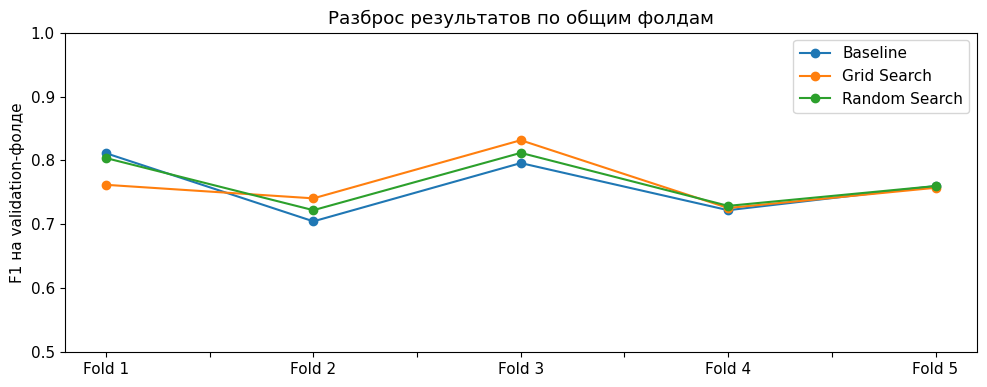

In [10]:
fold_columns = [f'split{i}_test_score' for i in range(N_FOLDS)]
fold_scores = pd.DataFrame({
    'Baseline': baseline_fold_scores,
    'Grid Search': grid_results.loc[grid_search.best_index_, fold_columns].astype(float).to_numpy(),
    'Random Search': random_results.loc[random_search.best_index_, fold_columns].astype(float).to_numpy(),
}, index=[f'Fold {i + 1}' for i in range(N_FOLDS)])
stability = pd.DataFrame({
    'CV mean': fold_scores.mean(),
    'CV std': fold_scores.std(ddof=0),
    'Минимум': fold_scores.min(),
    'Максимум': fold_scores.max(),
})
display(fold_scores.round(4))
display(stability.round(4))
fold_scores.plot(marker='o', ylim=(0.5, 1), figsize=(10, 4))
plt.ylabel('F1 на validation-фолде')
plt.title('Разброс результатов по общим фолдам')
plt.tight_layout()
plt.show()

Стандартное отклонение F1 уменьшилось с 0.0410 у исходной конфигурации
до 0.0364 у Grid и 0.0370 у Random. Random имеет чуть более высокое среднее,
Grid — чуть меньший разброс, но различие мало относительно вариативности фолдов.
Диапазоны Grid — 0.7257–0.8317, Random — 0.7222–0.8119.
Пять разбиений не дают основания считать малую разницу стратегий статистически убедительной.
Среднее качество и устойчивость являются разными характеристиками.

## 10. Итоговая проверка на фиксированном test

После завершения обоих поисков, диагностики и фиксации основного решения
рассчитаны тестовые метрики исходной модели и двух оптимизированных вариантов.
Все три Pipeline уже обучены на полном train. Test не используется для изменения победителя.

,CV F1,CV std,Test Accuracy,Test Precision,Test Recall,Test F1,Изменение CV F1,Изменение Test F1
Модель,,,,,,,,
Baseline,0.7588,0.0410,0.7989,0.7895,0.6522,0.7143,0.0000,0.0000
Grid Search,0.7635,0.0364,0.8101,0.7869,0.6957,0.7385,0.0046,0.0242
Random Search,0.7654,0.0370,0.8101,0.8070,0.6667,0.7302,0.0065,0.0159


Зафиксированный до теста выбор: Random Search
Его Test F1: 0.7302


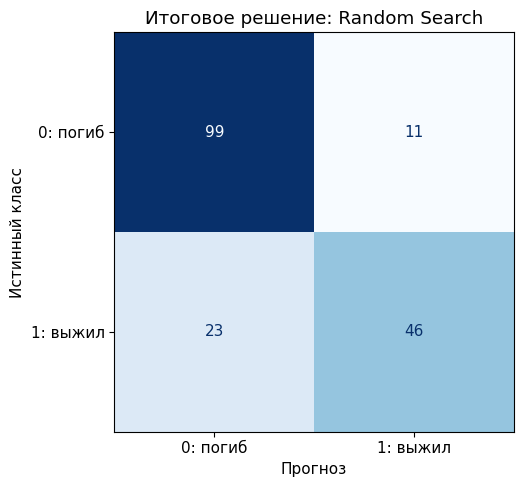

In [11]:
test_predictions = {}
rows = []
for name, fitted_model in models.items():
    prediction = fitted_model.predict(X_test)
    test_predictions[name] = prediction
    rows.append({
        'Модель': name,
        'CV F1': cv_means[name],
        'CV std': stability.loc[name, 'CV std'],
        'Test Accuracy': accuracy_score(y_test, prediction),
        'Test Precision': precision_score(y_test, prediction, zero_division=0),
        'Test Recall': recall_score(y_test, prediction, zero_division=0),
        'Test F1': f1_score(y_test, prediction, pos_label=1),
    })
comparison = pd.DataFrame(rows).set_index('Модель')
comparison['Изменение CV F1'] = comparison['CV F1'] - comparison.loc['Baseline', 'CV F1']
comparison['Изменение Test F1'] = comparison['Test F1'] - comparison.loc['Baseline', 'Test F1']
display(comparison.round(4))

y_pred = test_predictions[selected_name]
print('Зафиксированный до теста выбор:', selected_name)
print(f"Его Test F1: {comparison.loc[selected_name, 'Test F1']:.4f}")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['0: погиб', '1: выжил'],
    cmap='Blues', colorbar=False,
)
plt.title(f'Итоговое решение: {selected_name}')
plt.xlabel('Прогноз')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

## 11. Заключение

Оптимизированы n_estimators, learning_rate и max_depth у GradientBoostingClassifier из лабораторной № 2.
Оба поиска получили по 27 комбинаций и пять одинаковых фолдов — 135 CV fit плюс один refit каждый.

| Вариант | CV F1 | Test F1 | Изменение CV | Изменение test |
|---|---:|---:|---:|---:|
| Исходный | 0.7588 | 0.7143 | — | — |
| Grid Search | 0.7635 | 0.7385 | +0.0046 | +0.0242 |
| Random Search | 0.7654 | 0.7302 | +0.0065 | +0.0159 |

Grid выбрал 200 деревьев, learning_rate=0.05 и глубину 5.
Random выбрал 180 деревьев, learning_rate≈0.062528 и глубину 3.
Основное решение **Random Search** зафиксировано по максимальному CV F1 до тестовой оценки.
Его Test F1 = **0.7302**. Поиск улучшил исходную модель в обоих вариантах,
но порядок стратегий на CV и test различается. Причины могут включать малый объём выборки,
различия её состава и выбор максимума по CV. Победитель не изменялся по результатам test.

При равном числе попыток Random исследовал промежуточные значения и получил немного лучший CV;
Grid дал лучшие тестовые результаты в этом запуске. Универсальное превосходство стратегии не установлено.
Время обоих поисков измерено и приведено в разделе 7; оно зависит от нагрузки и выбранных конфигураций.
Срезы показывают подгонку при избыточном числе деревьев и слишком большом шаге,
а анализ фолдов — сохраняющуюся вариативность качества.

Тест из лабораторной № 2 повторно использован для фиксированного сравнения и не является новым слепым набором.
После тестовой таблицы параметры не корректировались. Скрытая проверка преподавателя недоступна.